# 01 · Data and exploratory analysis

What is in the file, what is wrong with it, and what `02_data_cleaning.ipynb` must fix.
Every section says what we check and what we found. Numbers quoted elsewhere come from `results/eda_numbers.json`, written at the end;
the charts are saved as `figures/eda_*.png`.

A note on units: one row is one rating of one company by one agency on one date. We call it a **firm-year** (a company rated by two agencies in the same year gives two). We count both firm-years and companies.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import binomtest, chi2_contingency
from sklearn.metrics import roc_auc_score

DATA = Path("../data/corporate_ratings_for_candidates_new.csv")
FIG, RES = Path("../figures"), Path("../results")
IG_GRADES = ["AAA", "AA", "A", "BBB"]
LETTERS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC", "CC", "C", "D"]          # best to worst
BANDS = ["AA and above", "A", "BBB", "BB", "B", "CCC and below"]
BAND_OF = {"AAA": 0, "AA": 0, "A": 1, "BBB": 2, "BB": 3, "B": 4, "CCC": 5, "CC": 5, "C": 5, "D": 5}
MARKET_PER_SHARE = ["enterpriseValueMultiple", "operatingCashFlowPerShare", "freeCashFlowPerShare"]
SIDE = {"IG": "#2a78d6", "SG": "#e07b39"}
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
EDA = {}          # numbers of record for this notebook


def save(fig, name):
    """Save a chart as figures/eda_<name>.png and show it."""
    fig.tight_layout()
    fig.savefig(FIG / f"eda_{name}.png", dpi=150)
    plt.show()

## 1. The raw file

In [2]:
raw = pd.read_csv(DATA, parse_dates=["Date"], date_format="%m/%d/%Y")
RATIOS = raw.select_dtypes("number").columns.drop("cashPerShare").tolist()     # the 24 ratios used
FEATURES = [c for c in RATIOS if c not in MARKET_PER_SHARE]                    # 21 an unrated firm has
print(raw.shape, "| numeric ratios:", raw.select_dtypes("number").shape[1])
print("companies:", raw.Name.nunique(), "| agencies:", raw["Rating Agency Name"].nunique(),
      "| sectors:", raw.Sector.nunique())
EDA.update(raw_rows=len(raw), raw_companies=raw.Name.nunique())

(2434, 30) | numeric ratios: 25
companies: 593 | agencies: 5 | sectors: 12


## 2. Duplicates
**Check:** are there repeated rows, and is every repeated (company, agency, date) an exact copy of the whole row?

In [3]:
key = ["Name", "Rating Agency Name", "Date"]
dup_row, dup_key = raw.duplicated(), raw.duplicated(key)
print("exact duplicate rows:", dup_row.sum(), f"({dup_row.mean():.1%} of the file)")
print("same rows flagged by both checks:", (dup_row == dup_key).all())
copies = raw[raw.duplicated(keep=False)].groupby(list(raw.columns), dropna=False).size()
print("copies per duplicated row:", copies.unique())
EDA.update(duplicate_rows=int(dup_row.sum()), duplicate_share=round(dup_row.mean(), 3))

exact duplicate rows: 405 (16.6% of the file)
same rows flagged by both checks: True
copies per duplicated row: [2]


**Found:** 405 rows (16.6%) are exact copies, each appearing twice, and the whole-row and key checks flag the same rows.
They are dropped; left in, a copy could sit in both training and test data.

## 3. The corrupt row
**Check:** does any firm-year look wrong in every column at once?

In [4]:
corrupt = raw[RATIOS].abs().median(axis=1) > 1e4          # typical ratio in the tens of thousands
bad = raw[corrupt]
print(bad[["Name", "Rating", "Rating Agency Name", "Date", "Sector"]].drop_duplicates().to_string(index=False),
      "| copies:", len(bad))
typical = raw.loc[~corrupt, RATIOS].median()
scaled = (bad[RATIOS].iloc[0] / 1e6 / typical).dropna()
print(f"divided by 10^6, relative to the typical firm-year: median {scaled.median():.2f}x,"
      f" range {scaled.min():.1f}x to {scaled.max():.1f}x")

       Name Rating Rating Agency Name       Date Sector
Company 590     AA    Rating agency 5 2016-10-07 Energy | copies: 2


divided by 10^6, relative to the typical firm-year: median 0.65x, range 0.0x to 2.4x


**Found:** one firm-year (Company 590, AA, 2016, present twice) has every ratio about 10⁶ times too large; divided by 10⁶ it looks normal.
It is dropped, everywhere, including any naive baseline. Rescaling would be a guess.

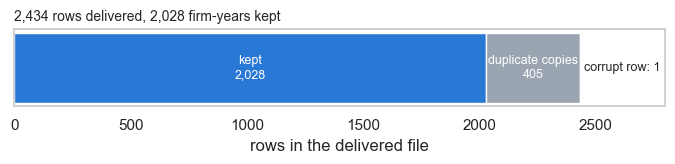

In [5]:
# Firm-years for the rest of this notebook: duplicates and the corrupt row removed, nothing else changed
X = raw[~corrupt].drop_duplicates().reset_index(drop=True)
X = X.assign(year=X.Date.dt.year, IG=X.Rating.isin(IG_GRADES).astype(int),
             letter_idx=X.Rating.map({r: i for i, r in enumerate(LETTERS)}),
             band=X.Rating.map(BAND_OF).map(dict(enumerate(BANDS))))
X["SG"] = 1 - X.IG
parts = pd.Series({"kept": len(X), "duplicate copies": int(dup_row.sum()),
                   "corrupt row": len(raw) - int(dup_row.sum()) - len(X)})
fig, ax = plt.subplots(figsize=(7, 1.8))
left = 0
for (label, n), color in zip(parts.items(), ["#2a78d6", "#9aa5b1", "#d64545"], strict=True):
    ax.barh(0, n, left=left, color=color)
    if n > 100:
        ax.text(left + n / 2, 0, f"{label}\n{n:,}", ha="center", va="center", color="white", fontsize=9)
    left += n
ax.text(left + 15, 0, "corrupt row: 1", va="center", fontsize=9)
ax.set(xlim=(0, len(raw) * 1.15), yticks=[], xlabel="rows in the delivered file")
ax.set_title(f"{len(raw):,} rows delivered, {len(X):,} firm-years kept", loc="left", fontsize=10)
ax.grid(False)
save(fig, "duplicates")

## 4. Clean data: firm-years, companies, years

In [6]:
per_company = X.groupby("Name").size()
print("firm-years:", len(X), "| companies:", X.Name.nunique(),
      "| firm-years per company:", per_company.describe()[["min", "50%", "max"]].to_dict())
print("firm-years by year:", X.year.value_counts().sort_index().to_dict())
print(f"2012–16 share: {(X.year >= 2012).mean():.1%}")
EDA.update(clean_firm_years=len(X), clean_companies=X.Name.nunique(), firm_years_per_company_max=int(per_company.max()),
           year_min=int(X.year.min()), year_max=int(X.year.max()), share_2012_16=round((X.year >= 2012).mean(), 3))

firm-years: 2028 | companies: 592 | firm-years per company: {'min': 1.0, '50%': 3.0, 'max': 7.0}
firm-years by year: {2005: 1, 2009: 1, 2010: 9, 2011: 58, 2012: 357, 2013: 312, 2014: 383, 2015: 480, 2016: 427}
2012–16 share: 96.6%


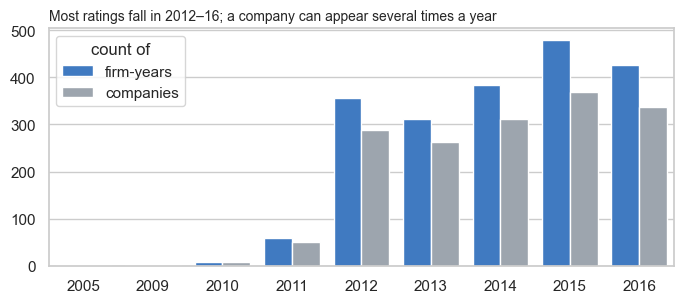

In [7]:
by_year = X.groupby("year").agg(**{"firm-years": ("Name", "size"), "companies": ("Name", "nunique")})
fig, ax = plt.subplots(figsize=(7, 3.2))
sns.barplot(data=by_year.reset_index().melt("year", var_name="count of", value_name="n"),
            x="year", y="n", hue="count of", palette=["#2a78d6", "#9aa5b1"], ax=ax)
ax.set(xlabel="", ylabel="")
ax.set_title("Most ratings fall in 2012–16; a company can appear several times a year", loc="left", fontsize=10)
save(fig, "years")

**Found:** 2,028 firm-years from 592 companies; each company appears 1–7 times. Ratings run 2005–2016, but 97% fall in 2012–16.
Because companies repeat, every model test must keep a company's firm-years together (grouped by `Name`).

## 5. Is `Name` a safe company identifier?
**Check:** one sector per name, no spelling variants, no identical statements under two names.

In [8]:
print("names with more than one sector:", (X.groupby("Name").Sector.nunique() > 1).sum())
print("names not of the form 'Company N':", (~X.Name.str.fullmatch(r"Company \d+")).sum())
shared = X.groupby([X[c].round(9) for c in RATIOS], dropna=False).Name.nunique()
print("statements shared by two names:", (shared > 1).sum())

names with more than one sector: 0
names not of the form 'Company N': 0


statements shared by two names: 0


**Found:** none of the three. Nothing in the data suggests one company under two names, so grouping by `Name` is sound.

## 6. Rating scale and target
The data carry letter grades only (AAA … D), with no 1/2/3 modifiers. On Moody's scale a **notch** is one step on the modified scale
(Baa1 → Baa2, and also Baa3 → Ba1, the step from investment to speculative grade). A one-letter move here can be 1 to 5 notches,
so we speak of **grades** and claim no notch precision.

| Data | Moody's | Side |
|---|---|---|
| AAA, AA, A, BBB | ≈ Aaa, Aa, A, Baa | investment grade (IG) |
| BB, B | ≈ Ba, B | speculative grade (SG) |
| CCC | ≈ Caa | SG |
| CC, C | ≈ Ca | SG |
| D | no Moody's symbol (S&P/Fitch default; Moody's C is the closest) | SG |

Agencies' letter scales are treated as comparable; the IG/SG cut is the same for every agency.

**Target:** `SG` = 1 for BB and below. The model estimates the probability of a speculative-grade rating, not a probability of default.

In [9]:
by_letter = X.groupby("Rating").agg(firm_years=("Name", "size"), companies=("Name", "nunique")).reindex(LETTERS)
print(by_letter.T.to_string())
print(f"\nSG share: {X.SG.mean():.1%} of firm-years | companies ever rated SG: {X.groupby('Name').SG.max().mean():.1%}")
print("6 bands:", X.band.value_counts().reindex(BANDS).to_dict())
EDA.update(sg_share=round(X.SG.mean(), 3), firm_years_by_letter=by_letter.firm_years.to_dict())

Rating      AAA  AA    A  BBB   BB    B  CCC  CC  C  D
firm_years    7  88  398  671  490  302   64   5  2  1
companies     3  41  156  271  226  144   43   5  2  1

SG share: 42.6% of firm-years | companies ever rated SG: 54.7%
6 bands: {'AA and above': 95, 'A': 398, 'BBB': 671, 'BB': 490, 'B': 302, 'CCC and below': 72}


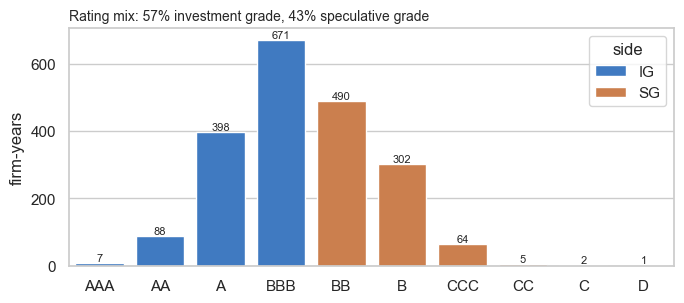

In [10]:
mix = by_letter.reset_index().assign(side=lambda d: np.where(d.Rating.isin(IG_GRADES), "IG", "SG"))
fig, ax = plt.subplots(figsize=(7, 3.2))
sns.barplot(data=mix, x="Rating", y="firm_years", hue="side", palette=SIDE, dodge=False, ax=ax)
ax.bar_label(ax.containers[0], fontsize=8)
ax.bar_label(ax.containers[1], fontsize=8)
ax.set(xlabel="", ylabel="firm-years")
ax.set_title(f"Rating mix: {1 - X.SG.mean():.0%} investment grade, {X.SG.mean():.0%} speculative grade",
             loc="left", fontsize=10)
save(fig, "rating_mix")

**Found:** 57/43 IG/SG, well balanced. The extremes are thin (7 AAA, 1 D firm-year), so the 6-band view merges them: AA and above, CCC and below.

## 7. Agencies
**Check:** how many firm-years each agency rates after cleaning, and how often two agencies agree on the same company.
Agreement uses **one pair per company** (the two ratings closest in time, at most 365 days apart), so no company counts twice.

In [11]:
by_agency = X.groupby("Rating Agency Name").agg(firm_years=("Name", "size"), companies=("Name", "nunique"))
print(by_agency.T.to_string())
EDA.update(agency_firm_years=by_agency.firm_years.to_dict())

r = X[["Name", "Rating Agency Name", "Date", "letter_idx", "IG"]]
pairs = r.merge(r, on="Name")
pairs = pairs[pairs["Rating Agency Name_x"] < pairs["Rating Agency Name_y"]]
pairs["gap_days"] = (pairs.Date_x - pairs.Date_y).abs().dt.days
one = pairs[pairs.gap_days <= 365].sort_values(["Name", "gap_days"]).groupby("Name").head(1)
same_side = (one.IG_x == one.IG_y).mean()
print(f"\n{len(one)} companies with two agencies: same letter {np.mean(one.letter_idx_x == one.letter_idx_y):.1%}"
      f" | within one grade {np.mean((one.letter_idx_x - one.letter_idx_y).abs() <= 1):.1%}"
      f" | same IG/SG side {same_side:.1%}")
EDA.update(agency_pairs_companies=len(one), agency_same_side=round(same_side, 3))

Rating Agency Name  Rating agency 1  Rating agency 2  Rating agency 3  Rating agency 4  Rating agency 5
firm_years                      603              100              744              579                2
companies                       238               76              298              325                2

152 companies with two agencies: same letter 55.3% | within one grade 94.7% | same IG/SG side 86.2%


In [12]:
# Is one agency stricter on the same company? Sign test per agency: how often it says SG when the other says IG.
pvals = {}
for a in sorted(X["Rating Agency Name"].unique()):
    ax_, ay_ = one[one["Rating Agency Name_x"] == a], one[one["Rating Agency Name_y"] == a]
    stricter = ((ax_.IG_x == 0) & (ax_.IG_y == 1)).sum() + ((ay_.IG_y == 0) & (ay_.IG_x == 1)).sum()
    milder = ((ax_.IG_x == 1) & (ax_.IG_y == 0)).sum() + ((ay_.IG_y == 1) & (ay_.IG_x == 0)).sum()
    if stricter + milder:
        pvals[a] = binomtest(int(stricter), int(stricter + milder)).pvalue
p_min = min(pvals.values())
print(f"smallest p = {p_min:.2f}, Bonferroni-adjusted {min(1, len(pvals) * p_min):.2f} ({len(pvals)} agencies)")
EDA.update(agency_sign_test_min_p=round(p_min, 3))

smallest p = 0.09, Bonferroni-adjusted 0.46 (5 agencies)


**Found:** agency 5 has only 2 firm-years left after cleaning. On the 152 companies with two agencies, the IG/SG side agrees 86%.
No agency is significantly stricter on the same company (small samples, so this is not proof of none).
Agency is never a model input: an unrated company has none.

## 8. Missing values
**Check:** which columns have gaps, and do the gaps carry information?

In [13]:
miss = X[RATIOS + ["cashPerShare"]].isna().sum()
print(miss[miss > 0].sort_values(ascending=False).to_string())
EDA.update(missing_share_cash_per_share=round(X.cashPerShare.isna().mean(), 3),
           missing_share_equity_multiplier=round(X.companyEquityMultiplier.isna().mean(), 3))

cashPerShare               1114
returnOnEquity              340
companyEquityMultiplier     101


In [14]:
# cashPerShare: if no ratio and not the rating can predict where it is missing, there is no sign the gaps carry information
m = X.cashPerShare.isna().astype(int)
best = max(abs(roc_auc_score(m[X[c].notna()], X.loc[X[c].notna(), c]) - 0.5) + 0.5 for c in RATIOS)
print(f"best AUC for predicting cashPerShare-missing: {best:.3f} | from the rating: {roc_auc_score(m, X.letter_idx):.3f}")
EDA.update(cash_missing_best_auc=round(best, 3))

best AUC for predicting cashPerShare-missing: 0.529 | from the rating: 0.498


In [15]:
# ROE: missing more often for weaker grades. Rebuild it with DuPont (net margin x asset turnover x equity multiplier).
roe_missing = X.returnOnEquity.isna()
dupont = X.netProfitMargin * X.assetTurnover * X.companyEquityMultiplier
rebuilt = dupont[roe_missing].dropna()
print(f"rebuildable missing ROE that is negative: {(rebuilt < 0).mean():.0%} (n = {len(rebuilt)})"
      f" | reported ROE that is negative: {(X.returnOnEquity < 0).mean():.0%}")
EDA.update(roe_missing_rebuilt_negative_share=round((rebuilt < 0).mean(), 3), roe_missing_rebuilt=len(rebuilt))

rebuildable missing ROE that is negative: 100% (n = 322) | reported ROE that is negative: 0%


band                     AA and above     A   BBB    BB     B  CCC and below
returnOnEquity                    2.0   5.0   8.0  23.0  38.0           49.0
companyEquityMultiplier           4.0   4.0   5.0   7.0   4.0            3.0
cashPerShare                     53.0  55.0  56.0  53.0  55.0           57.0


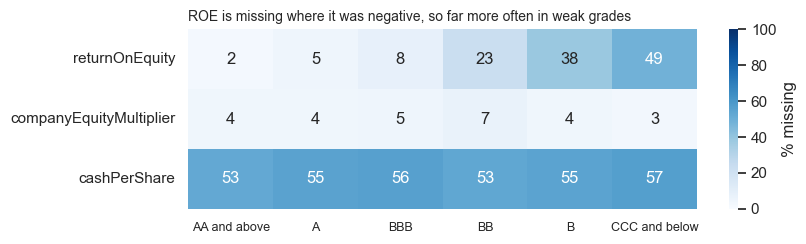

In [16]:
# Where the source file has gaps, by band: censored ROE follows the grade, the other gaps do not.
gaps = ["returnOnEquity", "companyEquityMultiplier", "cashPerShare"]
by_band = X[gaps].isna().groupby(X.band).mean().reindex(BANDS).T.mul(100)
print(by_band.round(0).to_string())
EDA.update(roe_missing_by_band=by_band.loc["returnOnEquity"].round(1).to_dict())
fig, ax = plt.subplots(figsize=(8.5, 2.6))
sns.heatmap(by_band, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar_kws={"label": "% missing"}, ax=ax)
ax.set(xlabel="", ylabel="")
ax.tick_params(axis="x", labelsize=9)
ax.set_title("ROE is missing where it was negative, so far more often in weak grades", loc="left", fontsize=10)
save(fig, "missingness")

In [17]:
# Equity multiplier: do the gaps differ between IG and SG?
cem_missing = X.companyEquityMultiplier.isna()
print(f"equity multiplier missing: IG {cem_missing[X.IG == 1].mean():.1%} vs SG {cem_missing[X.SG == 1].mean():.1%}"
      f" (chi-square p = {chi2_contingency(pd.crosstab(cem_missing, X.SG))[1]:.2f})")
gap = 1 - X.debtRatio
cem = X.companyEquityMultiplier
rel = ((1 / gap - cem).abs() / cem.abs())[(gap.abs() > 0.02) & cem.notna()]
print(f"identity equity multiplier = 1 / (1 - debt ratio): median relative error {rel.median():.3f}")
EDA.update(equity_identity_median_error=round(rel.median(), 3))

equity multiplier missing: IG 4.5% vs SG 5.7% (chi-square p = 0.26)
identity equity multiplier = 1 / (1 - debt ratio): median relative error 0.011


**Found:**
- `cashPerShare` (55% missing): no ratio and not the rating predicts where it is missing (AUC ≈ 0.5), so there is no evidence the gaps carry information.
  These checks cannot prove the gaps are random; they find no link. It is dropped.
- ROE was **censored**: every rebuildable missing ROE is negative and no reported ROE is. Filling it with a median would give loss-makers a healthy ROE, so 02 rebuilds it with DuPont and flags it.
- The equity multiplier (5% missing) is missing about as often for IG as for SG (no evidence the gaps carry information); 02 rebuilds it from the balance-sheet identity (1% error).
  Where equity is within 2% of zero the identity is unstable; 02 tries ROE ÷ ROA there first and uses the identity as computed as a last resort, never a median.

## 9. Impossible liquidity values
**Check:** quick assets are part of current assets, and cash is part of quick assets, so cash ratio ≤ quick ratio ≤ current ratio must hold.

In [18]:
quick_bad = X.quickRatio > X.currentRatio * 1.001
cash_bad = X.cashRatio > X.quickRatio * 1.001
sg_bad, sg_all = 1 - X.loc[quick_bad, "Rating"].isin(IG_GRADES).mean(), 1 - X.Rating.isin(IG_GRADES).mean()
print(f"quick > current: {quick_bad.sum()} firm-years, {X.loc[quick_bad, 'Name'].nunique()} companies"
      f" (SG share {sg_bad:.2f} vs {sg_all:.2f} overall)")
print(f"cash > quick:    {cash_bad.sum()} firm-years")
print(X.loc[quick_bad, "Name"].value_counts().head(3).to_dict(), "← the same companies, year after year")
factor = (X.quickRatio / X.currentRatio)[quick_bad]
print(f"quick / current where impossible: {(factor > 100).sum()} firm-years above 100x, largest {factor.max():.0f}x")
EDA.update(quick_gt_current=int(quick_bad.sum()), cash_gt_quick=int(cash_bad.sum()),
           quick_current_over_100x=int((factor > 100).sum()), quick_current_max_factor=round(factor.max()))

quick > current: 132 firm-years, 65 companies (SG share 0.43 vs 0.43 overall)
cash > quick:    41 firm-years
{'Company 89': 6, 'Company 101': 6, 'Company 211': 5} ← the same companies, year after year
quick / current where impossible: 3 firm-years above 100x, largest 824x


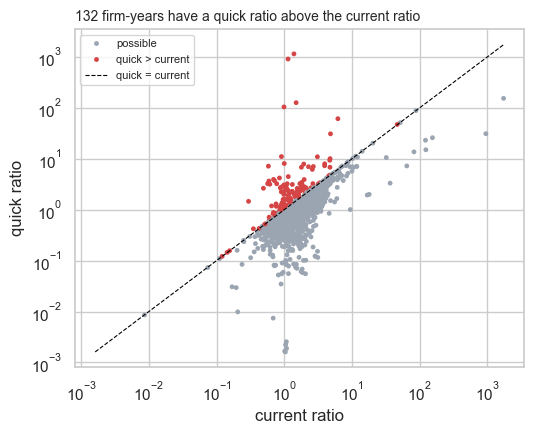

In [19]:
pos = X[(X.currentRatio > 0) & (X.quickRatio > 0)]
impossible = quick_bad[pos.index].map({True: "quick > current", False: "possible"})
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.scatterplot(data=pos, x="currentRatio", y="quickRatio", hue=impossible, hue_order=["possible", "quick > current"],
                palette=["#9aa5b1", "#d64545"], s=12, linewidth=0, ax=ax)
lims = [pos[["currentRatio", "quickRatio"]].min().min(), pos[["currentRatio", "quickRatio"]].max().max()]
ax.plot(lims, lims, color="black", lw=0.8, ls="--", label="quick = current")
ax.set(xscale="log", yscale="log", xlabel="current ratio", ylabel="quick ratio")
ax.legend(title="", fontsize=8)
ax.set_title(f"{quick_bad.sum()} firm-years have a quick ratio above the current ratio", loc="left", fontsize=10)
save(fig, "liquidity")

**Found:** 132 firm-years have quick > current ratio (3 of them by a factor of over 100, up to 824), and 41 have cash > quick. They repeat within companies,
so they look like a definition problem in the source, not distress. 02 sets the impossible value missing.

## 10. Negative equity
**Check:** a debt ratio above 1 means liabilities exceed assets. Does the reported equity multiplier agree?

In [20]:
over_one = X.debtRatio > 1
reported_pos = X.companyEquityMultiplier > 0
print(f"debt ratio > 1: {over_one.sum()} firm-years"
      f" | of which the reported equity multiplier is positive: {(over_one & reported_pos).sum()}")
EDA.update(debt_ratio_over_1=int(over_one.sum()),
           debt_ratio_over_1_positive_multiplier=int((over_one & reported_pos).sum()))
cols = ["Name", "Rating", "debtRatio", "companyEquityMultiplier", "debtEquityRatio"]
print(X.loc[over_one & reported_pos, cols].round(3).head(6).to_string(index=False))

debt ratio > 1: 109 firm-years | of which the reported equity multiplier is positive: 11
       Name Rating  debtRatio  companyEquityMultiplier  debtEquityRatio
 Company 44     AA      1.769                    1.088            1.913
Company 201      B      1.003                    3.362            3.389
Company 207      A      1.003                    2.406            2.381
Company 399      A      1.004                   22.955           22.593
  Company 5      A      1.000                  156.192          155.444
Company 414     BB      1.008                    5.313            5.304


**Found:** 11 firm-years have a debt ratio above 1 (mostly just above) but a positive reported equity multiplier and debt/equity, including AA and A names.
So 02 builds the `negative_equity` flag from the equity multiplier and uses the debt ratio only where the multiplier is missing.

## 11. Outliers
**Check:** how heavy are the tails, and are the extreme values consistent with each other or random noise?

In [21]:
num = X[RATIOS]
tails = (num.max() / num.quantile(0.99)).abs().sort_values()
print("largest value / 99th percentile, by ratio: median", round(tails.median()), "| min", round(tails.min()),
      "| max", f"{tails.max():.0e}")
# Return on assets = net margin x asset turnover. If extreme values were noise, this identity would break where they occur.
implied = X.netProfitMargin * X.assetTurnover
err = (X.returnOnAssets - implied).abs() / (implied.abs() + 1e-3)
print(f"ROA identity: median relative error {err.median():.4f}; firm-years off by more than 50%: {(err > 0.5).sum()}")

largest value / 99th percentile, by ratio: median 117 | min 1 | max 7e+05
ROA identity: median relative error 0.0066; firm-years off by more than 50%: 0


**Found:** most ratios have a few values over a hundred times their 99th percentile (up to about 10⁶), but the identities still hold:
these are real blow-ups where a denominator (revenue, equity) is close to zero, more common in weak firms.
They are kept and clipped at the 1st/99th percentile **inside** the modelling pipeline, learned on training folds only (notebook 03).

## 12. Suspected reporting artefacts and sign traps
**Check:** values whose meaning differs from the column name.

In [22]:
gm = X.grossProfitMargin >= 0.99
EDA.update(gross_margin_099_share=round(gm.mean(), 3))
cem = X.companyEquityMultiplier.fillna(1 / (1 - X.debtRatio))
roe_trap = (cem < 0) & (X.netProfitMargin < 0) & (X.returnOnEquity > 0)
ocf_neg = X.operatingCashFlowSalesRatio < 0
checks = [("gross margin ≥ 0.99", gm), ("ROE > 0 from losses / negative equity", roe_trap),
          ("negative operating cash flow", ocf_neg), ("payables turnover = 0", X.payablesTurnover == 0),
          ("days sales outstanding = 0", X.daysOfSalesOutstanding == 0)]
for label, mask in checks:
    sg = 1 - X.loc[mask, "Rating"].isin(IG_GRADES).mean()
    print(f"{label:40s} {mask.sum():4d} firm-years, {X.loc[mask, 'Name'].nunique():3d} companies, SG share {sg:.2f}")
print("\ngross margin ≥ 0.99, top sectors:", X.loc[gm, "Sector"].value_counts().head(3).to_dict())
fcf = X.freeCashFlowOperatingCashFlowRatio
print(f"FCF/OCF median with negative OCF: {fcf[ocf_neg].median():.2f} vs {fcf[~ocf_neg].median():.2f} otherwise")

gross margin ≥ 0.99                       414 firm-years, 133 companies, SG share 0.43
ROE > 0 from losses / negative equity      35 firm-years,  23 companies, SG share 1.00
negative operating cash flow               66 firm-years,  44 companies, SG share 0.88
payables turnover = 0                     261 firm-years,  90 companies, SG share 0.51
days sales outstanding = 0                194 firm-years,  65 companies, SG share 0.40

gross margin ≥ 0.99, top sectors: {'Energy': 138, 'Public Utilities': 105, 'Consumer Services': 45}
FCF/OCF median with negative OCF: 1.43 vs 0.63 otherwise


**Found** (each is fixed in 02):
- Gross margin ≥ 0.99 (20% of firm-years, mostly Energy and Utilities): most likely cost of goods sold not reported (a suspected artefact: the data cannot confirm it). To be set missing and flagged.
- ROE when equity is negative: losses ÷ negative equity gives a positive ROE. ROE must be **missing** when equity < 0, with flags for negative equity and negative ROE.
- FCF/OCF when operating cash flow is negative: two negatives look like strong cash conversion. To be set missing and flagged.
- Zero payables turnover and zero days sales outstanding look like placeholders (suspected), to be flagged.

## 13. Which ratios separate IG from SG
**Check:** on all firm-years (every sector is in scope, see section 14), how well does each statement ratio, as delivered, rank SG above IG on its own?
AUC 0.5 is no signal; the direction says whether higher values go with SG.

In [23]:
scope = X                       # every sector, Finance included (section 14)
auc = {}
for c in FEATURES:
    ok = scope[c].notna()
    a = roc_auc_score(scope.SG[ok], scope.loc[ok, c])
    auc[c] = (round(max(a, 1 - a), 3), "higher = SG" if a > 0.5 else "higher = IG")
auc = pd.DataFrame(auc, index=["AUC", "direction"]).T.sort_values("AUC", ascending=False)
print(auc.to_string())
EDA.update(univariate_auc=auc.AUC.to_dict())

                                      AUC    direction
returnOnCapitalEmployed             0.722  higher = IG
returnOnAssets                      0.719  higher = IG
pretaxProfitMargin                  0.705  higher = IG
ebitPerRevenue                      0.701  higher = IG
netProfitMargin                     0.698  higher = IG
operatingProfitMargin               0.665  higher = IG
operatingCashFlowSalesRatio         0.605  higher = IG
debtRatio                           0.605  higher = SG
returnOnEquity                      0.592  higher = IG
currentRatio                        0.579  higher = SG
quickRatio                          0.574  higher = SG
effectiveTaxRate                    0.562  higher = IG
cashRatio                           0.559  higher = SG
grossProfitMargin                   0.534  higher = IG
companyEquityMultiplier             0.532  higher = SG
assetTurnover                       0.529  higher = IG
debtEquityRatio                     0.529  higher = SG
daysOfSale

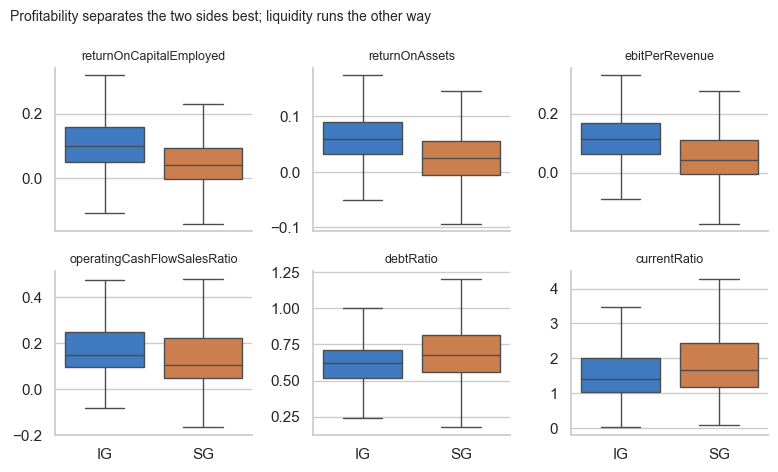

In [24]:
shown = ["returnOnCapitalEmployed", "returnOnAssets", "ebitPerRevenue", "operatingCashFlowSalesRatio",
         "debtRatio", "currentRatio"]
long = scope.assign(side=np.where(scope.SG == 1, "SG", "IG")).melt("side", value_vars=shown, var_name="ratio")
g = sns.catplot(data=long, x="side", y="value", hue="side", col="ratio", col_wrap=3, kind="box",
                order=["IG", "SG"], palette=SIDE, showfliers=False, sharey=False, height=2.4, aspect=1.1)
g.set_titles("{col_name}", size=9)
g.set_axis_labels("", "")
g.figure.suptitle("Profitability separates the two sides best; liquidity runs the other way", x=0.02, ha="left", fontsize=10)
save(g.figure, "ig_sg_ratios")

**Found:** profitability separates IG from SG best: return on capital employed and return on assets reach AUC 0.72 on their own,
and the margins 0.67–0.71. Leverage is weaker (debt ratio 0.61), and ROE as delivered only 0.59, because its negative values were removed (section 8). Liquidity runs the other way: a higher current ratio goes with SG (AUC 0.58).
No single ratio is enough, which is why the model combines them.

## 14. What goes to modelling

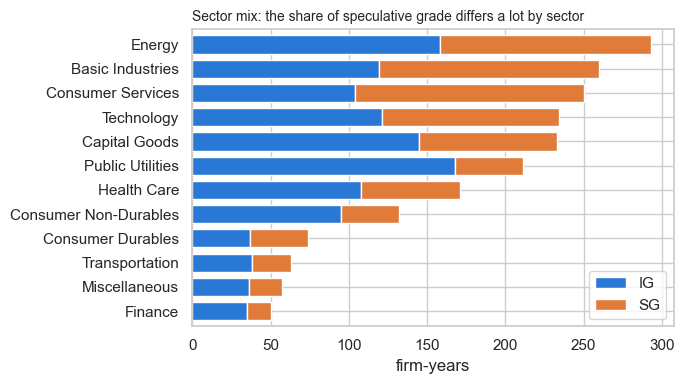

In [25]:
by_sector = X.groupby("Sector").agg(firm_years=("SG", "size"), sg_share=("SG", "mean")).sort_values("firm_years")
EDA.update(sector_sg_share=by_sector.sg_share.round(3).to_dict())
counts = X.assign(side=np.where(X.SG == 1, "SG", "IG")).groupby(["Sector", "side"]).size().unstack()
fig, ax = plt.subplots(figsize=(7, 4))
counts.reindex(by_sector.index).plot.barh(stacked=True, color=SIDE, ax=ax, width=0.75)
ax.set(xlabel="firm-years", ylabel="")
ax.legend(title="", loc="lower right")
ax.set_title("Sector mix: the share of speculative grade differs a lot by sector", loc="left", fontsize=10)
save(fig, "sector_mix")

**Check:** is Finance different enough to leave out? Banks and insurers are rated under their own agency methods, and a bank's balance sheet looks nothing like an industrial company's: a debt ratio near 0.9 and almost no revenue against its assets. Compare Finance's leverage with the other sectors, and count the Finance companies with a bank-like balance sheet (latest statement).

In [26]:
lev = X.groupby("Sector")[["debtRatio", "debtEquityRatio", "assetTurnover"]].median()
others = lev.drop("Finance")
print(pd.DataFrame({"Finance": lev.loc["Finance"], "rank of 12 (1 = highest)": lev.rank(ascending=False).loc["Finance"].astype(int),
                    "other sectors, lowest": others.min(), "other sectors, highest": others.max()}).round(2).to_string())
fin_last = X[X.Sector == "Finance"].sort_values("Date").groupby("Name").tail(1)
bank_like = (fin_last.debtRatio > 0.85) & (fin_last.assetTurnover < 0.15)
print(f"Finance companies with a bank-like balance sheet (debt ratio > 0.85, asset turnover < 0.15): {bank_like.sum()} of {len(fin_last)}")
EDA.update(finance_debt_ratio_median=round(lev.loc["Finance", "debtRatio"], 3),
           finance_debt_ratio_rank=int(lev.debtRatio.rank(ascending=False)["Finance"]),
           finance_companies=len(fin_last), finance_bank_like=int(bank_like.sum()))

                 Finance  rank of 12 (1 = highest)  other sectors, lowest  other sectors, highest
debtRatio           0.73                         3                   0.57                    0.76
debtEquityRatio     2.73                         1                   1.30                    2.45
assetTurnover       0.31                        12                   0.33                    1.19
Finance companies with a bank-like balance sheet (debt ratio > 0.85, asset turnover < 0.15): 2 of 17


In [27]:
print(f"in scope (all sectors): {len(scope)} firm-years, {scope.Name.nunique()} companies, SG share {scope.SG.mean():.1%}")
print("statement ratios an unrated firm has:", len(FEATURES))
EDA.update(scope_firm_years=len(scope), scope_companies=scope.Name.nunique(), scope_sg_share=round(scope.SG.mean(), 3),
           finance_firm_years=int((X.Sector == "Finance").sum()), n_features=len(FEATURES))
numbers = {k: int(v) if isinstance(v, np.integer) else v for k, v in EDA.items()}
_ = (RES / "eda_numbers.json").write_text(json.dumps(numbers, indent=1, default=int))

in scope (all sectors): 2028 firm-years, 592 companies, SG share 42.6%
statement ratios an unrated firm has: 21


**Found:** sectors differ a lot in SG share, from 20% (Public Utilities) to 58% (Consumer Services), so the sector is a model input.
Finance stays in scope. Its median debt ratio (0.73) is the third highest of 12 sectors and inside the range of the others (0.57–0.76); its debt/equity is the highest and its asset turnover the lowest, but only a little beyond the other sectors. Only 2 of its 17 companies have a bank-like balance sheet. Banks and insurers are rated under their own agency methods, so such a balance sheet deserves an analyst's look; that is noted, not made a rule.
Modelling uses 2,028 firm-years from 592 companies, 42.6% SG, with 21 statement ratios, the flags built in 02, and the sector.